# Phase 6 — Feature Engineering

Builds leakage-safe, documented features for future price forecasting (Phase 8), market-arrivals modelling (Phase 9) and supply analysis (Phase 10) from the Phase 5 cleaned tables. The logic lives in `Code/features/pipeline.py`; this notebook states the feature contract, runs the pipeline and validates it. **No EDA, model training or forecasting happens here.**

## INDEX

1. [Objective and Scope](#1)
2. [Inputs and Verified Schema](#2)
3. [Feature-Engineering Contract](#3)
4. [Time Features](#4)
5. [Price History Features](#5)
6. [Market-Arrivals History Features](#6)
7. [Weather and APY Features](#7)
8. [Feature Registry](#8)
9. [Run the Feature Pipeline](#9)
10. [Generation Audit: Rows, Types, Missingness](#10)
11. [Validation and Leakage Checks](#11)
12. [Diagnostic Figures](#12)
13. [Limitations and Decisions Needed Before Modelling](#13)
14. [Completion Summary and Phase 7 Handoff](#14)


<a id="1"></a>
## 1. Objective and Scope

**Objective**: add predictor features to every cleaned mandi record without changing the records, inventing values, or letting any target or future information leak into a predictor.

**In scope**: calendar features; historical price and arrivals features (lags, calendar-window statistics, changes); lagged weather windows and lagged APY context.
**Out of scope**: EDA (Phase 7), any model, target transformation, imputation, train/test splitting.

`arrivals_tonnes` describes market arrivals — supply-side market activity — and is never called demand (A-02).

<a id="2"></a>
## 2. Inputs and Verified Schema

In [1]:
import os, sys, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
sys.path.append(str(PROJECT_ROOT))
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 110)

from Code.features import pipeline as f6
from Code.cleaning import pipeline as c5
from Code.integration import pipeline as p4

CROPS = p4.load_selected_crops()
FIG = Path("Outputs/Figures")
inv = []
for crop in CROPS:
    path = c5.CLEAN_DIR / f"mandi_cleaned_{crop.lower()}.parquet"
    d = pd.read_parquet(path, columns=f6.SERIES + ["reported_date", "usable_modal_price", "usable_arrivals", "dup_status"])
    inv.append({"crop": crop, "path": str(path), "rows": len(d),
                "series (crop x market x variety)": d.groupby(f6.SERIES, observed=True).ngroups,
                "first_date": d["reported_date"].min().date(), "last_date": d["reported_date"].max().date(),
                "usable_modal_price": int(d["usable_modal_price"].sum()), "usable_arrivals": int(d["usable_arrivals"].sum()),
                "rows sharing a series-date": int(d.duplicated(f6.SERIES + ["reported_date"], keep=False).sum()),
                "conflict_unresolved rows": int((d["dup_status"] == "conflict_unresolved").sum())})
display(pd.DataFrame(inv))
pd.read_parquet(c5.CLEAN_DIR / "mandi_cleaned_wheat.parquet").dtypes.astype(str).to_frame("dtype").T

,crop,path,rows,series (crop x market x variety),first_date,last_date,usable_modal_price,usable_arrivals,rows sharing a series-date,conflict_unresolved rows
0,Onion,Processed_Data\cleaned\mandi_cleaned_onion.parquet,2623671,3924,2000-10-19,2024-02-02,2595611,2623528,68,68
1,Potato,Processed_Data\cleaned\mandi_cleaned_potato.parquet,2764417,4003,2000-10-19,2024-02-02,2731271,2764191,164,164
2,Wheat,Processed_Data\cleaned\mandi_cleaned_wheat.parquet,2593279,5279,2001-03-16,2024-02-01,2579015,2593120,106,106


,source_row,crop,state,district,market,variety,commodity_group,arrivals_tonnes,min_price_rs_per_quintal,max_price_rs_per_quintal,modal_price_rs_per_quintal,reported_date,dup_key_count,dup_type,apy_year,apy_year_lag1,apy_state,apy_district,apy_district_match,apy_annual_available,...,temperature_2m_min,rain_sum,relative_humidity_2m_mean,wind_speed_10m_mean,et0_fao_evapotranspiration,weather_match,dup_status,n_identical_copies,min_price_status,max_price_status,modal_price_status,arrivals_status,min_gt_max,modal_outside_range,price_ratio_to_ref,price_extreme_level,arrivals_ratio_to_ref,arrivals_extreme_level,usable_modal_price,usable_arrivals
dtype,int64,category,category,category,category,category,category,float64,float64,float64,float64,datetime64[ns],int32,category,category,category,category,category,category,bool,...,float64,float64,float64,float64,float64,category,category,int16,category,category,category,category,bool,bool,float64,category,float64,category,bool,bool


The inputs are the three Phase 5 files (47 columns, one row per distinct observation). Within a **series = (crop, state, district, market, variety)** the only rows sharing a date are the Phase 5 `conflict_unresolved` rows — so variety, not just market, defines a price series (a market quotes several varieties per day at different prices).

<a id="3"></a>
## 3. Feature-Engineering Contract

| Item | Decision |
|---|---|
| Observation grain | one row per Phase 5 row (`source_row`); output rows = input rows, nothing added or removed |
| Distinct series | (crop, state, district, market, variety); no feature crosses a series |
| Prediction-time assumption | a row dated *t* is predicted using information available at the end of day *t−1* (A-20). Every history feature uses rows dated **strictly before t**; the row's own price/arrivals and same-day weather are never predictors |
| Eligible price history | rows with `usable_modal_price` (Phase 5): excludes unresolved conflicts, modal outside [min,max], suspected scale errors, missing modal |
| Eligible arrivals history | rows with `usable_arrivals` (Phase 5): excludes conflicts and suspected entry errors; genuine zero arrivals are included |
| Ineligible rows | stay in the table and receive features computed from eligible history; they simply never *become* history |
| Lags | two explicit kinds: **previous available observation** (`*_prev_obs`, with `*_prev_obs_days_ago`) and **exact calendar-day lags** (`*_lag_1d`, `*_lag_7d`: NaN if not reported that exact day) |
| Windows | **calendar-day** windows `[t − w days, t)` for w = 7, 30, 90 (pandas time-based rolling, `closed="left"`) with an explicit `count` |
| Missing data | no imputation, forward-fill, back-fill or zero-fill; insufficient history → NaN (`count` = 0) |
| Roles | identifier / target / eligibility_flag / audit_only / predictor — recorded per column in the registry |

**Why calendar windows are supported**: reporting is irregular but dense — the median gap between eligible observations is 1 day and ≈96–98% of gaps are ≤ 7 days, so 7/30/90-day calendar windows are meaningful; `*_count` and `*_prev_obs_days_ago` expose irregularity rather than hiding it. A 1-day *observation* lag is not labelled as a calendar lag.

<a id="4"></a>
## 4. Time Features

`year`, `month`, `quarter`, `day_of_week` (mandi reporting differs by weekday), cyclical `month_sin`/`month_cos`, `agri_year_start` (July–June agricultural year, consistent with APY and D-19) and `imd_season` — the India Meteorological Department's meteorological seasons (winter Jan–Feb, pre-monsoon Mar–May, monsoon Jun–Sep, post-monsoon Oct–Dec).

**Deliberately not created**: crop *harvest* seasons. Harvest and arrival timing differs by crop and region and no verified crop calendar exists in the project, so a "Rabi/Kharif harvest" flag would be an unverified claim. All calendar features are known in advance for any date.

<a id="5"></a>
## 5. Price History Features

For each series, from eligible (`usable_modal_price`) rows dated before *t*:
- `modal_prev_obs`, `modal_prev_obs_days_ago`, `min_price_prev_obs`, `max_price_prev_obs` — the previous available observation;
- `modal_pct_change_prev_obs` = previous / second-previous − 1 (valid because Phase 5 set zero prices to missing, so all eligible prices are > 0);
- `modal_lag_1d`, `modal_lag_7d` — exact calendar-day lags;
- `modal_roll{7,30,90}d_{mean,median,std,count}` — calendar windows before *t*.

<a id="6"></a>
## 6. Market-Arrivals History Features

The same structure for `arrivals_tonnes` from `usable_arrivals` rows: `arrivals_prev_obs`, `arrivals_prev_obs_days_ago`, `arrivals_lag_{1,7}d`, `arrivals_roll{7,30,90}d_{mean,median,std,count}`, and `arrivals_change_prev_obs` as an **absolute** change in tonnes — a percentage change is undefined when the earlier value is a genuine zero. Same-day arrivals are a target, never a predictor: they are only known once the day's trading is reported.

<a id="7"></a>
## 7. Weather and APY Features

**Weather** (Phase 4 policy unchanged: exact state+district location, no proxies, no new data): computed on the Phase 4 daily panel at its own (location, date) grain, then joined many-to-one: the previous calendar day's temperature, rain, humidity and ET0, and trailing windows (`wx_rain_sum_{7,30,90}d`, `wx_temp_mean_mean_{7,30}d`, `wx_temp_max_mean_7d`, `wx_rh_mean_mean_7d`, `wx_et0_sum_30d`). A window is only filled when **all** its days exist, so windows reaching before 2001-01-01 or after 2022-12-31 stay missing. The Phase 4 same-day weather columns are **not** carried into the feature table (they describe day *t* itself).

**APY**: annual production, area and yield of the record's APY district for agricultural year *t − 2* (`*_lag2`). Lag 1 is not used: the only observed publication date (APY 2022-23 released on 14-12-2023, codebook) implies ~6 months' delay, so the previous year's figures are unavailable for roughly the first half of each agricultural year (A-19). The value is constant within a district × agricultural year — context, not a daily observation.

<a id="8"></a>
## 8. Feature Registry

Every output column with its role, task, definition, inputs, grouping, window, missing-value behaviour, prediction-time availability and leakage safeguard (written to `Processed_Data/features_audit/feature_registry.csv`).

In [2]:
registry = f6.feature_registry()
print(registry["role"].value_counts().to_string())
registry

role
predictor           59
audit_only          10
identifier           9
target               4
eligibility_flag     2


,feature,role,task,definition,inputs,grouping,window_or_lag,missing_value_behaviour,available_at_prediction_time,leakage_risk_and_safeguard
0,source_row,identifier,-,key / traceability column (source_row links to Phase 4/5 rows),source_row,-,-,"never missing (market_code may be missing, Phase 4 D-22)",not a model input,row ids and dates must not be used as predictors
1,crop,identifier,-,key / traceability column (source_row links to Phase 4/5 rows),crop,-,-,"never missing (market_code may be missing, Phase 4 D-22)",not a model input,row ids and dates must not be used as predictors
2,state,identifier,-,key / traceability column (source_row links to Phase 4/5 rows),state,-,-,"never missing (market_code may be missing, Phase 4 D-22)",not a model input,row ids and dates must not be used as predictors
3,district,identifier,-,key / traceability column (source_row links to Phase 4/5 rows),district,-,-,"never missing (market_code may be missing, Phase 4 D-22)",not a model input,row ids and dates must not be used as predictors
4,market,identifier,-,key / traceability column (source_row links to Phase 4/5 rows),market,-,-,"never missing (market_code may be missing, Phase 4 D-22)",not a model input,row ids and dates must not be used as predictors
...,...,...,...,...,...,...,...,...,...,...
79,wx_et0_sum_30d,predictor,price / arrivals / supply,sum of et0_fao_evapotranspiration over the 30 calendar days before t,et0_fao_evapotranspiration,weather location (Phase 4 exact state+district),30 calendar days before t,NaN without a location or unless all w days lie inside 2001-01-01..2022-12-31,yes - uses only data dated < t,computed on the Phase 4 daily panel strictly before t; same-day weather excluded
80,apy_production_tonnes_lag2,predictor,supply / price context,APY annual production of the record's APY district for agricultural year agri_year_start-2 (Phase 4 apy_an...,"apy_annual.csv via apy_state, apy_district",crop x APY district,2 agricultural years,"NaN where no APY district, no annual row, or ambiguous annual value (D-20)",assumed yes (A-19): APY for year Y is assumed published before year Y+2 starts,"lag 2, not lag 1: lag-1 data is published months into the year (D-36); constant within district x agricult..."
81,apy_area_ha_lag2,predictor,supply / price context,APY annual area of the record's APY district for agricultural year agri_year_start-2 (Phase 4 apy_annual.csv),"apy_annual.csv via apy_state, apy_district",crop x APY district,2 agricultural years,"NaN where no APY district, no annual row, or ambiguous annual value (D-20)",assumed yes (A-19): APY for year Y is assumed published before year Y+2 starts,"lag 2, not lag 1: lag-1 data is published months into the year (D-36); constant within district x agricult..."
82,apy_yield_t_per_ha_lag2,predictor,supply / price context,APY annual yield of the record's APY district for agricultural year agri_year_start-2 (Phase 4 apy_annual....,"apy_annual.csv via apy_state, apy_district",crop x APY district,2 agricultural years,"NaN where no APY district, no annual row, or ambiguous annual value (D-20)",assumed yes (A-19): APY for year Y is assumed published before year Y+2 starts,"lag 2, not lag 1: lag-1 data is published months into the year (D-36); constant within district x agricult..."


<a id="9"></a>
## 9. Run the Feature Pipeline

Reads the Phase 5 tables and the Phase 4 weather panel / APY table (fingerprinted before and after), writes `Processed_Data/features/features_<crop>.parquet` and `Processed_Data/features_audit/`, and refuses input that already contains Phase 6 features.

In [3]:
import logging
logging.basicConfig(level=logging.INFO, format="%(message)s", force=True)
result = f6.run_features()
print("Run time (s):", result["seconds"])
result["row_counts"]

Onion: 2623671 rows, 85 columns


Potato: 2764417 rows, 85 columns


Wheat: 2593279 rows, 85 columns


Phase 6 finished in 108.7s


Run time (s): 108.7


,crop,input_rows,output_rows,series,input_columns,output_columns,rows_with_usable_modal_target,rows_with_usable_arrivals_target
0,Onion,2623671,2623671,3924,47,85,2595611,2623528
1,Potato,2764417,2764417,4003,47,85,2731271,2764191
2,Wheat,2593279,2593279,5279,47,85,2579015,2593120


<a id="10"></a>
## 10. Generation Audit: Rows, Types, Missingness

Input and output row counts are identical for every crop (before/after comparison above: 47 → 85 columns, same rows). Missingness of the main features:

In [4]:
st = result["feature_statistics"]
key = ["modal_prev_obs", "modal_prev_obs_days_ago", "modal_lag_1d", "modal_lag_7d", "modal_roll7d_mean",
       "modal_roll30d_mean", "modal_roll90d_mean", "modal_roll30d_std", "modal_pct_change_prev_obs",
       "arrivals_prev_obs", "arrivals_lag_1d", "arrivals_roll30d_mean", "wx_rain_sum_30d", "wx_temp_mean_mean_7d",
       "apy_production_tonnes_lag2"]
st[st["column"].isin(key)].pivot(index="column", columns="crop", values="missing_pct").loc[key]

crop,Onion,Potato,Wheat
column,,,
modal_prev_obs,0.433,0.454,0.319
modal_prev_obs_days_ago,0.433,0.454,0.319
modal_lag_1d,28.828,25.336,34.294
modal_lag_7d,24.337,22.417,28.839
modal_roll7d_mean,3.695,3.384,4.549
modal_roll30d_mean,1.733,1.745,1.724
modal_roll90d_mean,1.233,1.290,1.065
modal_roll30d_std,2.655,2.553,3.099
modal_pct_change_prev_obs,0.579,0.644,0.528


Interpretation of the missingness (all by design, none imputed):
- `*_prev_obs`: missing only on each series' first eligible day (< 1%).
- `*_lag_1d` / `*_lag_7d`: missing 22–34% of the time (by crop) — the series simply did not report on that exact calendar day. This is why previous-observation lags exist separately.
- Rolling means: missing only when the window holds no eligible observation; shorter windows are missing more often.
- Weather: 75–76% missing — Phase 4 coverage (only 46 verified district locations) plus dates outside 2001–2022.
- APY lag-2: missing 51% (Onion), 34% (Potato), 4% (Wheat) — where the district has no APY link or APY has no annual value for that crop-year (Phase 4 found APY reports Onion for far fewer district-years than mandis trade it).

In [5]:
st[st["crop"] == "Wheat"][["column", "dtype", "non_missing", "missing_pct", "min", "median", "max"]]

,column,dtype,non_missing,missing_pct,min,median,max
170,source_row,int64,2593279,0.000,0.0,1296967.000,2593766.000
171,crop,category,2593279,0.000,NaN,NaN,NaN
172,state,category,2593279,0.000,NaN,NaN,NaN
173,district,category,2593279,0.000,NaN,NaN,NaN
174,market,category,2593279,0.000,NaN,NaN,NaN
...,...,...,...,...,...,...,...
250,wx_et0_sum_30d,float64,654225,74.772,42.9,135.790,300.190
251,apy_year_lag2,category,2593279,0.000,NaN,NaN,NaN
252,apy_production_tonnes_lag2,float64,2495441,3.773,0.7,288334.000,2053482.000
253,apy_area_ha_lag2,float64,2495959,3.753,0.5,99000.000,412568.000


<a id="11"></a>
## 11. Validation and Leakage Checks

1. The pipeline's own validation report (row preservation, registry coverage, a 1,000-comparison brute-force spot check per crop, input immutability).
2. An independent brute-force recomputation here with a different random sample.
3. A leakage probe: future values of one real series are replaced by an absurd number; features of earlier rows must not change.
4. The full project test suite (Phases 4–6).

In [6]:
result["validation_report"]

,crop,check,passed
0,Onion,row count preserved (input == output),True
1,Onion,same source_row set as Phase 5,True
2,Onion,registry covers every output column,True
3,Onion,brute-force spot check of history features (1000 comparisons),True
4,Onion,no history feature present before the series' first eligible observation,True
5,Onion,same-day weather columns not carried as predictors,True
6,Potato,row count preserved (input == output),True
7,Potato,same source_row set as Phase 5,True
8,Potato,registry covers every output column,True
9,Potato,brute-force spot check of history features (1000 comparisons),True


In [7]:
checks = {}
for crop in CROPS:
    cl = pd.read_parquet(c5.CLEAN_DIR / f"mandi_cleaned_{crop.lower()}.parquet")
    ft = pd.read_parquet(f6.FEATURE_DIR / f"features_{crop.lower()}.parquet")
    sc = f6.spot_check(ft, cl, n=150, seed=42)
    checks[f"{crop}: independent brute-force check ({len(sc)} comparisons)"] = bool(sc["match"].all())
    checks[f"{crop}: rows and source_row identical to Phase 5"] = bool(
        len(ft) == len(cl) and (ft["source_row"].to_numpy() == cl["source_row"].to_numpy()).all())
    checks[f"{crop}: targets carried unchanged"] = all(ft[c].equals(cl[c]) for c in [f6.MODAL, f6.ARR])
    pred = set(result["feature_registry"].query("role == 'predictor'")["feature"].str.split(" / ").explode())
    checks[f"{crop}: no target / id / date / same-day weather among predictors"] = not (pred & {
        f6.MODAL, f6.MIN, f6.MAX, f6.ARR, "source_row", "reported_date", "temperature_2m_mean", "rain_sum"})
    checks[f"{crop}: no price feature built from an empty window"] = bool(
        ft.loc[ft["modal_roll30d_count"] == 0, "modal_roll30d_mean"].isna().all())
    del cl, ft

# leakage probe on one real Wheat series: corrupt everything from the series' midpoint onwards
cl = pd.read_parquet(c5.CLEAN_DIR / "mandi_cleaned_wheat.parquet")
sizes = cl.groupby(f6.SERIES, observed=True).size()
key = sizes[sizes.between(300, 2000)].index[0]
one = cl.set_index(f6.SERIES).loc[key].reset_index()
mid = one["reported_date"].sort_values().iloc[len(one) // 2]
wx_empty = pd.DataFrame(columns=["weather_state", "weather_district", "reported_date"]).astype({"reported_date": "datetime64[ns]"})
apy_empty = f6.apy_lag_table(pd.read_csv(p4.OUT_DIR / "apy_annual.csv").head(0), "Wheat")
a = f6.build_features(one, wx_empty, apy_empty).set_index("source_row")
bad = one.copy()
bad.loc[bad["reported_date"] >= mid, [f6.MODAL, f6.MIN, f6.MAX, f6.ARR]] = 1e9
b = f6.build_features(bad, wx_empty, apy_empty).set_index("source_row")
hist = [c for c in a.columns if c.startswith(("modal_", "arrivals_", "min_price_prev", "max_price_prev"))
        and c not in (f6.MODAL, f6.ARR)]
upto = a["reported_date"] <= mid
checks[f"Leakage probe ({len(one)}-row Wheat series): corrupting values from {mid.date()} on leaves all "
       f"features up to and including that date unchanged"] = a.loc[upto, hist].equals(b.loc[upto, hist])
checks["Leakage probe sanity: later rows do change"] = not a.loc[~upto, hist].equals(b.loc[~upto, hist])
for k, v in checks.items():
    print(("PASS" if v else "FAIL"), "-", k)
assert all(checks.values()), "Phase 6 validation failed"
print("\nAll Phase 6 notebook validation checks passed.")

PASS - Onion: independent brute-force check (750 comparisons)
PASS - Onion: rows and source_row identical to Phase 5
PASS - Onion: targets carried unchanged
PASS - Onion: no target / id / date / same-day weather among predictors
PASS - Onion: no price feature built from an empty window
PASS - Potato: independent brute-force check (750 comparisons)
PASS - Potato: rows and source_row identical to Phase 5
PASS - Potato: targets carried unchanged
PASS - Potato: no target / id / date / same-day weather among predictors
PASS - Potato: no price feature built from an empty window
PASS - Wheat: independent brute-force check (750 comparisons)
PASS - Wheat: rows and source_row identical to Phase 5
PASS - Wheat: targets carried unchanged
PASS - Wheat: no target / id / date / same-day weather among predictors
PASS - Wheat: no price feature built from an empty window
PASS - Leakage probe (562-row Wheat series): corrupting values from 2006-04-07 on leaves all features up to and including that date un

C:\Users\aksha_q43exq6\AppData\Local\Temp\ipykernel_10508\2114238829.py:21: PerformanceWarning: indexing past lexsort depth may impact performance.
  one = cl.set_index(f6.SERIES).loc[key].reset_index()


In [8]:
tests = subprocess.run([sys.executable, "-m", "pytest", "Code/tests", "-q", "-p", "no:cacheprovider"],
                       capture_output=True, text=True)
print(tests.stdout[-3000:])
assert tests.returncode == 0, "Project test suite failed"
print("Full suite: Phase 4 + Phase 5 + Phase 6 tests (incl. re-run reproducibility and Phase 4/5 immutability).")

.............................................                            [100%]
45 passed in 339.87s (0:05:39)

Full suite: Phase 4 + Phase 5 + Phase 6 tests (incl. re-run reproducibility and Phase 4/5 immutability).


<a id="12"></a>
## 12. Diagnostic Figures

Two figures that validate the feature semantics (not EDA): how irregular reporting is, and that the trailing features only look backwards.

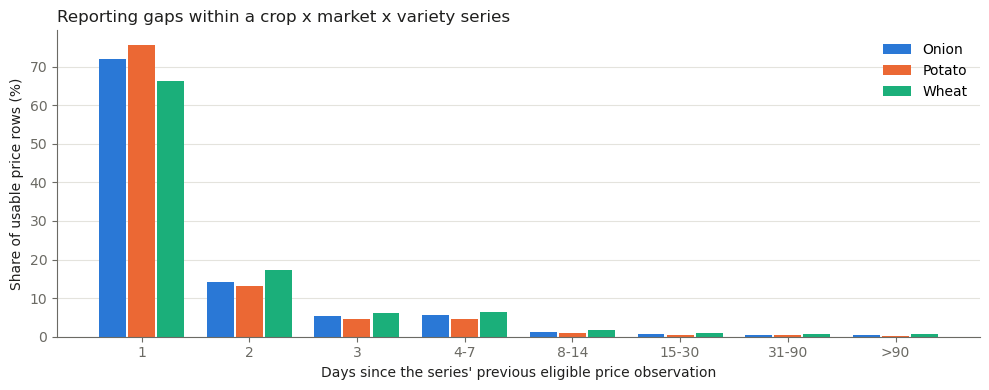

In [9]:
SERIES_C = ["#2a78d6", "#eb6834", "#1baf7a"]
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e4e3dd"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(figsize=(10, 4))
edges = [1, 2, 3, 4, 8, 15, 31, 91, 10**6]
labels = ["1", "2", "3", "4-7", "8-14", "15-30", "31-90", ">90"]
xx = np.arange(len(labels))
for i, crop in enumerate(CROPS):
    g = pd.read_parquet(f6.FEATURE_DIR / f"features_{crop.lower()}.parquet",
                        columns=["modal_prev_obs_days_ago", "usable_modal_price"])
    g = g.loc[g["usable_modal_price"], "modal_prev_obs_days_ago"].dropna()
    share = pd.cut(g, edges, right=False, labels=labels).value_counts(normalize=True).reindex(labels) * 100
    ax.bar(xx + (i - 1) * 0.27, share, 0.25, color=SERIES_C[i], label=crop)
ax.set_xticks(xx, labels)
ax.set_xlabel("Days since the series' previous eligible price observation")
ax.set_ylabel("Share of usable price rows (%)")
ax.set_title("Reporting gaps within a crop x market x variety series", loc="left", color=INK)
ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "phase06_reporting_gap_distribution.png", dpi=150); plt.show()

C:\Users\aksha_q43exq6\AppData\Local\Temp\ipykernel_10508\1626141192.py:4: PerformanceWarning: indexing past lexsort depth may impact performance.
  one = ft.set_index(f6.SERIES).loc[key].reset_index()


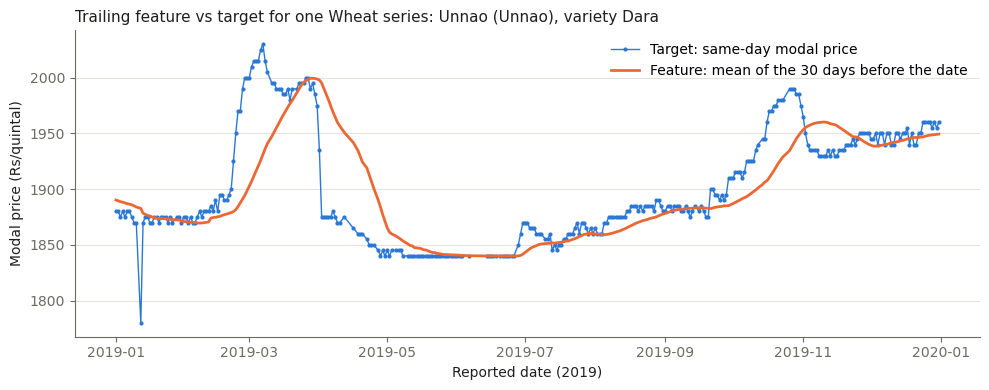

In [10]:
ft = pd.read_parquet(f6.FEATURE_DIR / "features_wheat.parquet")
sizes = ft[ft["usable_modal_price"]].groupby(f6.SERIES, observed=True).size()
key = sizes.idxmax()
one = ft.set_index(f6.SERIES).loc[key].reset_index()
one = one[(one["reported_date"] >= "2019-01-01") & (one["reported_date"] < "2020-01-01") & one["usable_modal_price"]]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(one["reported_date"], one[f6.MODAL], color=SERIES_C[0], linewidth=1, marker="o", markersize=2,
        label="Target: same-day modal price")
ax.plot(one["reported_date"], one["modal_roll30d_mean"], color=SERIES_C[1], linewidth=2,
        label="Feature: mean of the 30 days before the date")
ax.set_xlabel("Reported date (2019)"); ax.set_ylabel("Modal price (Rs/quintal)")
ax.set_title(f"Trailing feature vs target for one Wheat series: {key[3]} ({key[2]}), variety {key[4]}",
             loc="left", color=INK, fontsize=11)
ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "phase06_trailing_feature_example.png", dpi=150); plt.show()
del ft

The gap chart confirms the window semantics: most eligible observations follow a 1-day gap, but a real tail of multi-week gaps exists, which is why lags are split into exact calendar lags and previous-observation lags and why every window reports its `count`. In the series example the 30-day trailing mean follows the price with a delay — it reacts only after a move has happened, as a feature built strictly from past data must.

<a id="13"></a>
## 13. Limitations and Decisions Needed Before Modelling

**Limitations**
1. **Prediction-time assumption (A-20)**: features assume a forecast for day *t* is made with data up to the end of day *t−1* (a one-step / next-reporting-day setting). For an *h*-day-ahead forecast (Phase 8 anticipates 7–30 days) features must come from the forecast-origin row (or be recomputed with a cutoff of *t−h*); using these row-level features for a multi-day horizon would leak *h−1* days.
2. **APY lag-2 (A-19)** rests on a single observed publication date; if APY is published faster, lag 1 would be usable for part of the year.
3. **Weather** exists for ~25% of rows only (Phase 4 coverage) and not after 2022-12-31.
4. **Short series**: series with few eligible observations get mostly-missing history features; the `*_count` columns let a model or filter see this.
5. **Unresolved conflicts** (338 rows) and Phase 5 `review` rows are not targets in the usable views; `review` rows remain eligible history (Phase 5 policy) and may carry genuine but extreme values.
6. **No crop harvest-season feature** was created (no verified calendar).

**Must be decided in Phase 7/8 before modelling**: the forecast horizon(s) and information cutoff; whether targets use only `usable_*` rows (recommended) and how to treat `review` rows; any model-specific handling of missing features (only if fit on training data only); the evaluation split dates; and whether weather features are used only on the weather-covered subset.

<a id="14"></a>
## 14. Completion Summary and Phase 7 Handoff

**Phase 6 status: completed** — pipeline, registry, audit, notebook checks (including the leakage probe) and the full test suite pass (Section 11).

**Phase 7 (EDA) receives** `Processed_Data/features/features_{onion,potato,wheat}.parquet` (same rows as Phase 5, 85 columns) and `Processed_Data/features_audit/` (registry, row counts, feature statistics, validation report, fingerprints, manifest). Phase 7 should use the registry roles: explore targets against predictors only, keep `audit_only` and `eligibility_flag` columns out of any correlation-with-target ranking, and record which relationships are supported by evidence.